In [ ]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.6 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [ ]:
import keras

print(keras.__version__)

3.0.4


94765736/94765736 [==============================] - 1s 0us/step
調整X_train的圖片尺寸...
使用 ResNet50 模型預測訓練資料的特徵資料...
125/125 [==============================] - 13s 71ms/step
調整X_test的圖片尺寸...
使用 ResNet50 模型預測測試資料的特徵資料...
32/32 [==============================] - 4s 105ms/step
Epoch 1/14
125/125 - 4s - loss: 1.1338 - accuracy: 0.6267 - val_loss: 0.4969 - val_accuracy: 0.8320 - 4s/epoch - 34ms/step
Epoch 2/14
125/125 - 2s - loss: 0.5160 - accuracy: 0.8248 - val_loss: 0.4274 - val_accuracy: 0.8490 - 2s/epoch - 13ms/step
Epoch 3/14
125/125 - 1s - loss: 0.4048 - accuracy: 0.8558 - val_loss: 0.3957 - val_accuracy: 0.8560 - 1s/epoch - 11ms/step
Epoch 4/14
125/125 - 1s - loss: 0.3551 - accuracy: 0.8770 - val_loss: 0.3850 - val_accuracy: 0.8650 - 1s/epoch - 9ms/step
Epoch 5/14
125/125 - 1s - loss: 0.3142 - accuracy: 0.8888 - val_loss: 0.3727 - val_accuracy: 0.8740 - 1s/epoch - 9ms/step
Epoch 6/14
125/125 - 1s - loss: 0.2907 - accuracy: 0.8970 - val_loss: 0.4013 - val_accuracy: 0.8520 - 1s/epoch - 9ms/

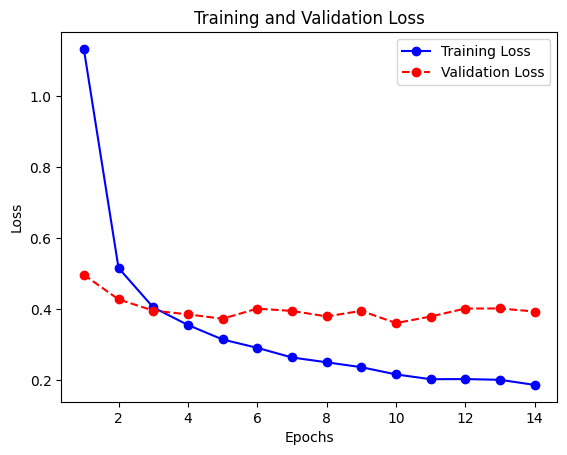

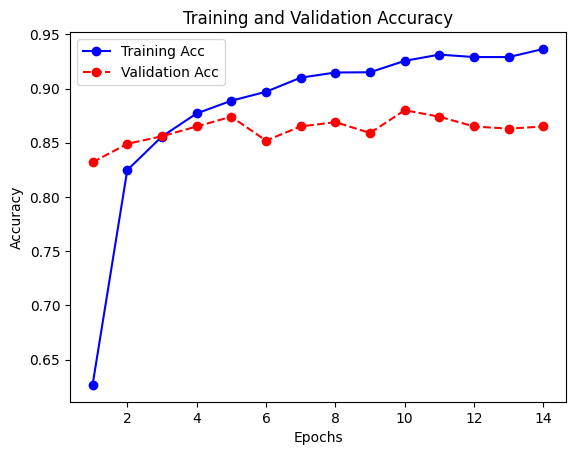

In [ ]:
import numpy as np
from keras.datasets import cifar10
from keras.applications.resnet50 import ResNet50, preprocess_input
from keras import Sequential
from keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
from keras.utils import to_categorical
from PIL import Image
import warnings

warnings.filterwarnings("ignore")
# 指定亂數種子
np.random.seed(10)
# 載入資料集
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# 打亂 2 個 Numpy 陣列
def randomize(a, b):
    permutation = list(np.random.permutation(a.shape[0]))
    shuffled_a = a[permutation]
    shuffled_b = b[permutation]

    return shuffled_a, shuffled_b

X_train, y_train = randomize(X_train, y_train)
X_test, y_test = randomize(X_test, y_test)
# 取出部分的訓練和測試資料
X_train = X_train[:4000]
y_train = y_train[:4000]
X_test = X_test[:1000]
y_test = y_test[:1000]
# One-hot編碼
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
# 載入 ResNet50 模型
resnet_model = ResNet50(weights="imagenet",
                        include_top=False,
                        input_shape=(200, 200, 3))
# 調整X_train的圖片尺寸
print("調整X_train的圖片尺寸...")
X_train_new = np.array(
  [np.asarray(Image.fromarray(X_train[i]).resize(
          (200, 200))) for i in range(0, len(X_train))])
X_train_new = X_train_new.astype("float32")
# 訓練資料的資料前處理
train_input = preprocess_input(X_train_new)
# 使用 ResNet50 模型預測訓練資料的特徵資料
print("使用 ResNet50 模型預測訓練資料的特徵資料...")
train_features = resnet_model.predict(train_input)
# 調整X_test的圖片尺寸
print("調整X_test的圖片尺寸...")
X_test_new = np.array(
  [np.asarray(Image.fromarray(X_test[i]).resize(
          (200, 200))) for i in range(0, len(X_test))])
X_test_new = X_test_new.astype("float32")
# 測試資料的資料前處理
test_input = preprocess_input(X_test_new)
# 使用 ResNet50 模型預測測試資料的特徵資料
print("使用 ResNet50 模型預測測試資料的特徵資料...")
test_features = resnet_model.predict(test_input)
# 定義模型
model = Sequential()
model.add(Input(shape=train_features.shape[1:]))
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))
# 編譯模型
model.compile(loss="categorical_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
history = model.fit(train_features, y_train,
                    validation_data=(test_features, y_test),
                    epochs=14, batch_size=32, verbose=2)
# 評估模型
print("\nTesting ...")
loss, accuracy = model.evaluate(test_features, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示圖表來分析模型的訓練過程
import matplotlib.pyplot as plt
# 顯示訓練和驗證損失
loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo-", label="Training Loss")
plt.plot(epochs, val_loss, "ro--", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo-", label="Training Acc")
plt.plot(epochs, val_acc, "ro--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()